## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

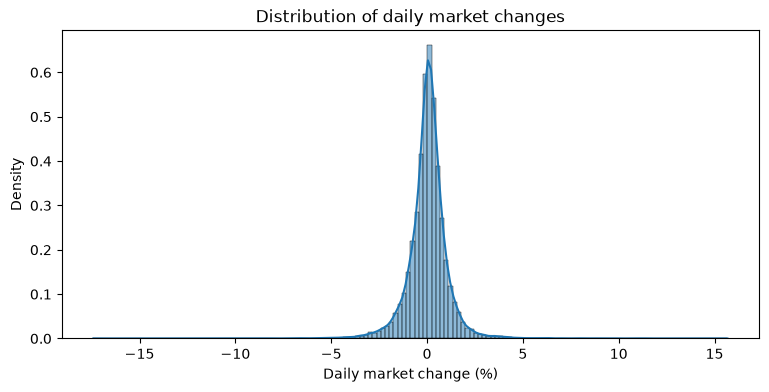

In [31]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

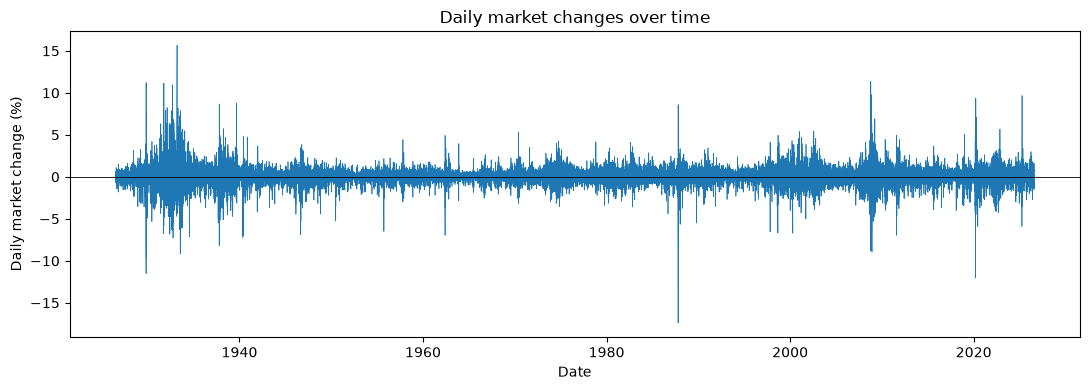

In [32]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [33]:
# Current market return
df['current_value'] = df['market_return_pct']

# Next market return
df['next_value'] = df['market_return_pct'].shift(-1)

df['current_cat'] = df['current_value'].apply(lambda x: 'Up' if x > 0 else 'Down' if x < 0 else 'Flat')

df['next_cat'] = df['next_value'].apply(lambda x: 'Up' if x > 0 else 'Down' if x < 0 else 'Flat')

In [34]:
df.head()

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,current_value,next_value,current_cat,next_cat
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,0.10,0.46,Up,Up
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,0.46,0.18,Up,Up
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,0.18,0.10,Up,Up
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,0.10,0.23,Up,Up
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,0.23,-0.70,Up,Down


In [35]:
pd.crosstab(index=df['current_cat'], columns=df['next_cat'], margins=True, normalize='index').round(3)

next_cat,Down,Flat,Up
current_cat,,,
Down,0.492,0.006,0.503
Flat,0.416,0.006,0.578
Up,0.410,0.007,0.583
All,0.446,0.007,0.547


Based on the data, up transitions are occur 54.7% of the time, which is more than down transitions occuring about 44.6% of the time. We are slightly more likely to transition from an up day to an up day (58.3%) than we are from a down day (50.3%)

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [36]:
df['return_categories'] = pd.cut(df['market_return_pct'], bins=[-np.inf, -1, -.1, .1, 1, np.inf], labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain'])
print('Number of Days in Each Category:', df['return_categories'].value_counts().sort_index())

Number of Days in Each Category: return_categories
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [37]:
n_bins = 21

df['y_t'] = pd.qcut(df['market_return_pct'], q=n_bins, labels=False)

#Shift
df['y_tp1'] = df['y_t'].shift(-1)
df['next_value'] = df['market_return_pct'].shift(-1)


_, edges = pd.qcut(df['market_return_pct'], q=n_bins, retbins=True)
print('Bin edges (%):', np.round(edges, 2))
print(df['y_t'].value_counts().sort_index())

Bin edges (%): [-17.41  -1.61  -1.07  -0.78  -0.57  -0.42  -0.3   -0.19  -0.11  -0.03
   0.04   0.11   0.18   0.26   0.34   0.44   0.54   0.67   0.84   1.09
   1.55  15.67]
y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1283
18    1225
19    1250
20    1238
Name: count, dtype: int64


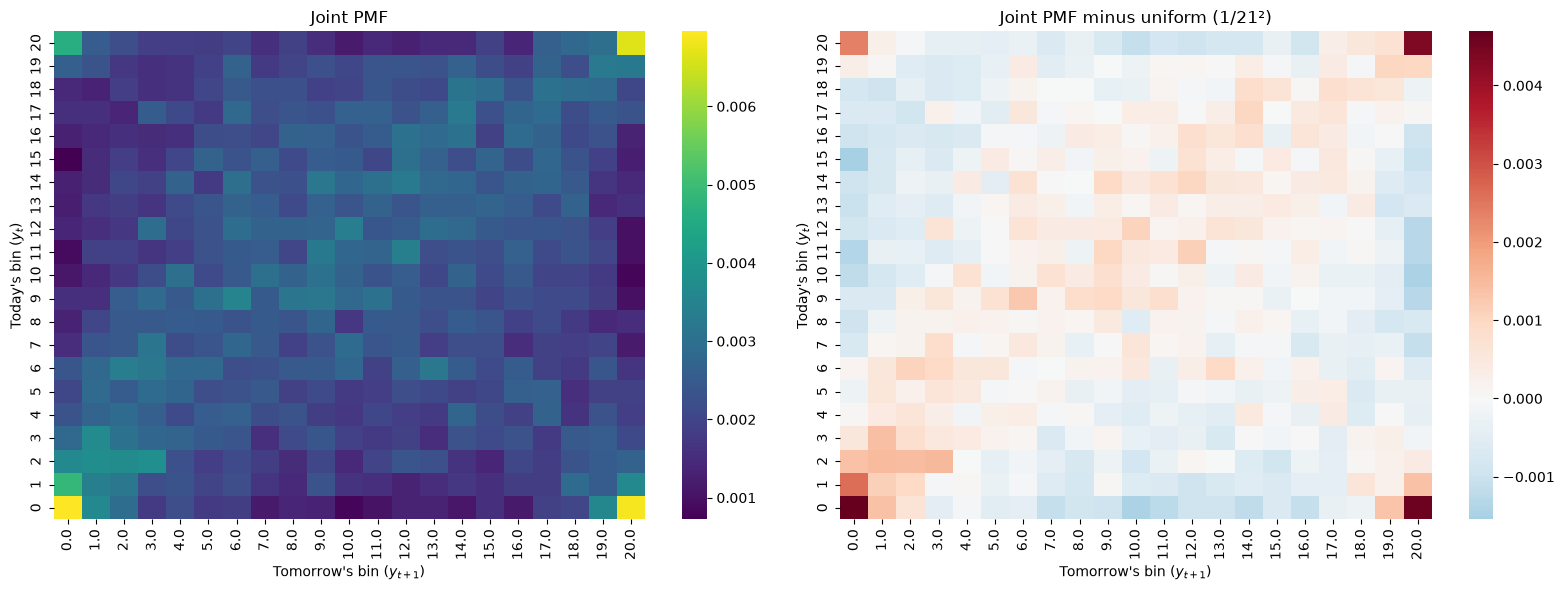

In [38]:
# Joint PMF
joint_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='all')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(joint_pmf, cmap='viridis', ax=axes[0])
axes[0].set(title='Joint PMF', xlabel='Tomorrow\'s bin ($y_{t+1}$)', ylabel='Today\'s bin ($y_t$)')

sns.heatmap(joint_pmf - 1 / n_bins**2, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set(title='Joint PMF minus uniform (1/21²)', xlabel='Tomorrow\'s bin ($y_{t+1}$)', ylabel='Today\'s bin ($y_t$)')
for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
plt.show()

Joint PMF: The raw heatmap looks close to flat, as every cell is near $1/21^2. This is because the bins are quantiles and so each row and column has roughly equal mass. There is a clear pattern that occurs. The our corners are dark, which means that extreme days are followed by extreme days, in either direction, while the middle rows/columns are slightly over-represented in the center and under-represented at the extremes. Big moves cluster together, and quiet days cluster together too.

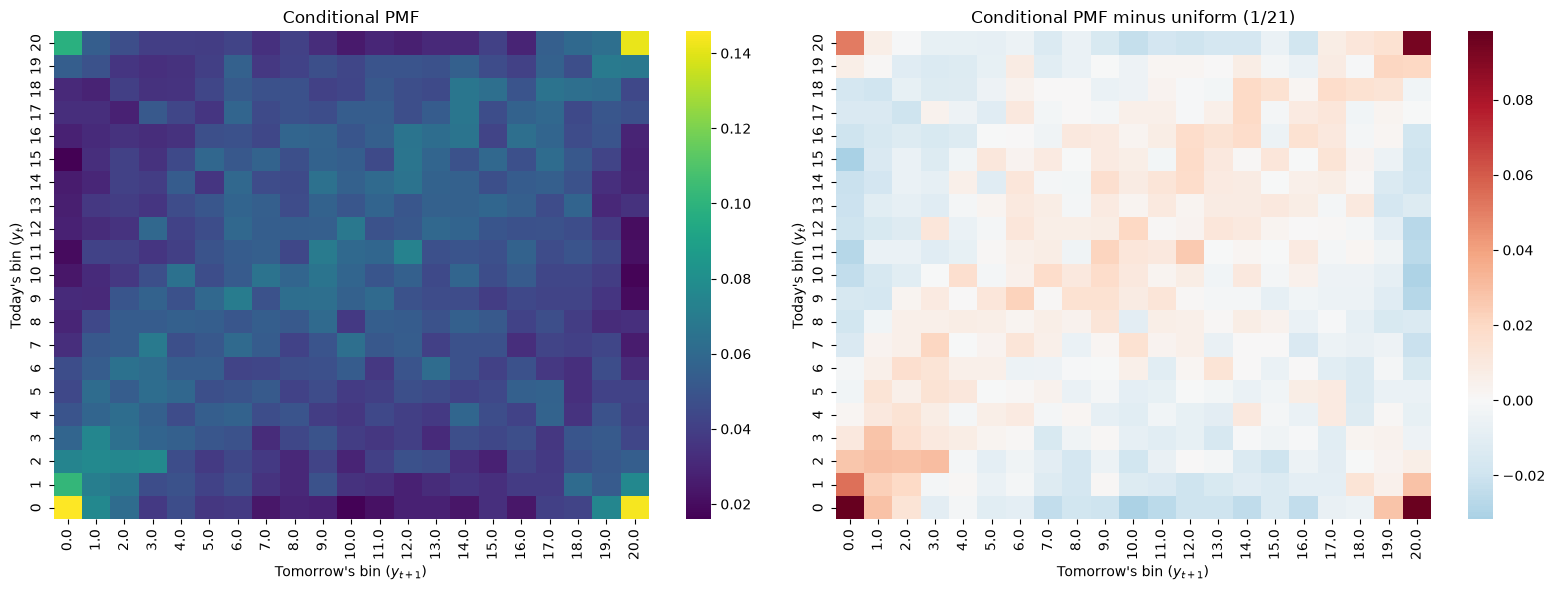

In [39]:
# Conditional PMF
cond_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cond_pmf, cmap='viridis', ax=axes[0])
axes[0].set(title='Conditional PMF', xlabel='Tomorrow\'s bin ($y_{t+1}$)', ylabel='Today\'s bin ($y_t$)')

sns.heatmap(cond_pmf - 1 / n_bins, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set(title='Conditional PMF minus uniform (1/21)', xlabel='Tomorrow\'s bin ($y_{t+1}$)', ylabel='Today\'s bin ($y_t$)')
for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
plt.show()

Conditional PMF: We have the same pattern. Given an extreme day the chance of another extreme day tomorrow is roughly 0.14–0.15 instead of the uniform 0.048 which is about about 3x more likely. Given a middle bin, tomorrow is a bit more likely to be in the middle as well. The deviations are symmetric which means that a huge loss makes a huge gain and a huge loss more likely. The table tells you about the size of tomorrow's move much more than its direction. Outside the corners, most rows are close to uniform.

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
0,1255.0,-0.014,2.140,-17.41,-0.915,-0.02,0.900,11.22
1,1253.0,-0.077,1.286,-7.36,-0.740,-0.02,0.600,6.36
2,1286.0,-0.097,1.228,-8.79,-0.710,-0.03,0.470,11.36
3,1280.0,-0.059,1.050,-8.28,-0.580,0.00,0.492,6.16
4,1230.0,-0.024,0.989,-6.89,-0.467,0.02,0.467,4.56
5,1226.0,-0.023,1.025,-11.23,-0.498,0.02,0.500,6.37
6,1371.0,-0.030,0.930,-3.94,-0.495,0.03,0.410,7.37
7,1206.0,-0.014,0.836,-3.40,-0.420,0.03,0.410,4.76
8,1198.0,0.026,0.853,-6.00,-0.390,0.03,0.440,5.49


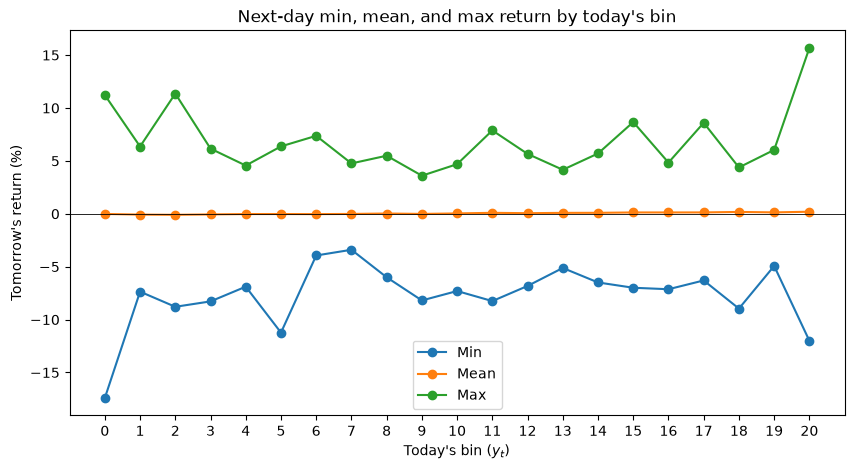

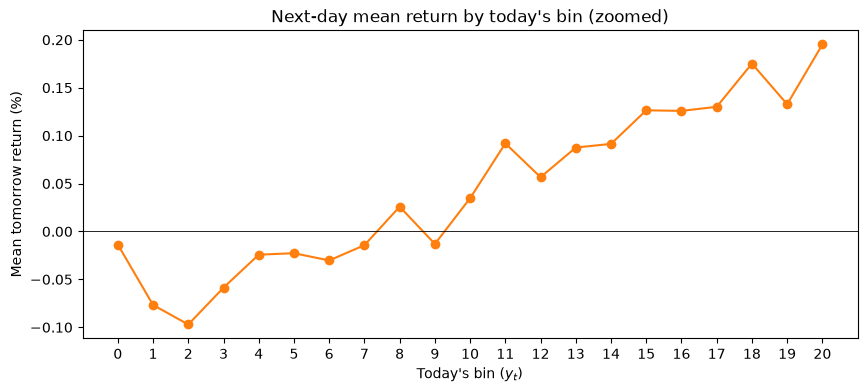

In [40]:
# Next-day summary stats by today's bin
next_stats = df.groupby('y_t')['next_value'].describe()
next_stats['std'] = df.groupby('y_t')['next_value'].std()
display(next_stats.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(next_stats.index, next_stats['min'], marker='o', label='Min')
ax.plot(next_stats.index, next_stats['mean'], marker='o', label='Mean')
ax.plot(next_stats.index, next_stats['max'], marker='o', label='Max')
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Today\'s bin ($y_t$)', ylabel='Tomorrow\'s return (%)',
       title='Next-day min, mean, and max return by today\'s bin', xticks=range(n_bins))
ax.legend()
plt.show()

# Zoom in on the mean, which is tiny relative to min/max
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(next_stats.index, next_stats['mean'], marker='o', color='C1')
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Today\'s bin ($y_t$)', ylabel='Mean tomorrow return (%)',
       title='Next-day mean return by today\'s bin (zoomed)', xticks=range(n_bins))
plt.show()

**Min / mean / max:** The min and max lines form a **"U" / funnel shape**: after extreme days in either direction (bins 0 and 20), tomorrow's range is far wider (e.g. −17% to +11% after the worst days, −12% to +16% after the best) than after middle days. The mean is nearly flat and close to zero on the scale of the min/max — it drifts up slightly from about −0.1% after bad days to about +0.2% after good days, a small momentum effect that is tiny compared to the spread.

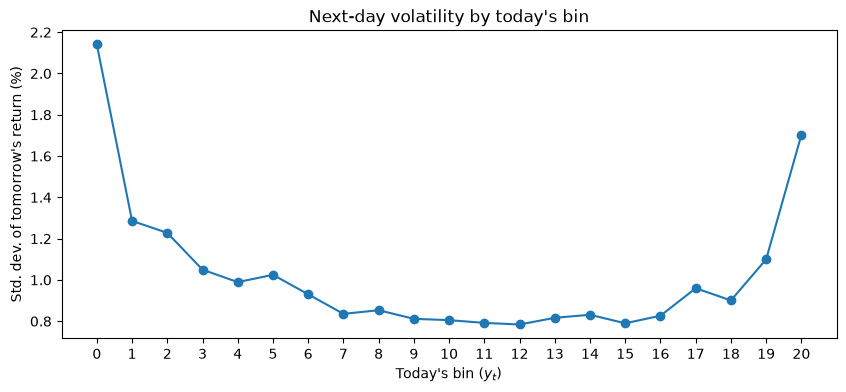

In [41]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(next_stats.index, next_stats['std'], marker='o')
ax.set(xlabel='Today\'s bin ($y_t$)', ylabel='Std. dev. of tomorrow\'s return (%)',
       title='Next-day volatility by today\'s bin', xticks=range(n_bins))
plt.show()

Standard deviation: It is a clear U-shape. Tomorrow's standard deviation is about 2.1% after the worst days and 1.7% after the best days, versus roughly 0.8% after middle days. It's also asymmetric which shows that volatility is higher after losses than after equally ranked gains.

How easy is it to predict the market? The direction of tomorrow's return is very hard to predict. The conditional PMF rows are close to uniform outside the extremes, and the conditional mean barely moves from zero relative to its spread. However what appears to be predictable is the volatility. An extreme day today strongly signals that tomorrow will also be a large move, though not which way. So today's state helps forecast risk, but offers little help forecasting returns.